## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Nguyen

**Date:** 10-12-26

In [97]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
---

Answer: As noise goes up, each cluster gets more and more spread out. Initially when the noise was 0.125 the clusters were easily seperatable, but as the noise grew the points spread out until I could no longer distinguish between the groups. 

<Axes: xlabel='x1', ylabel='x2'>

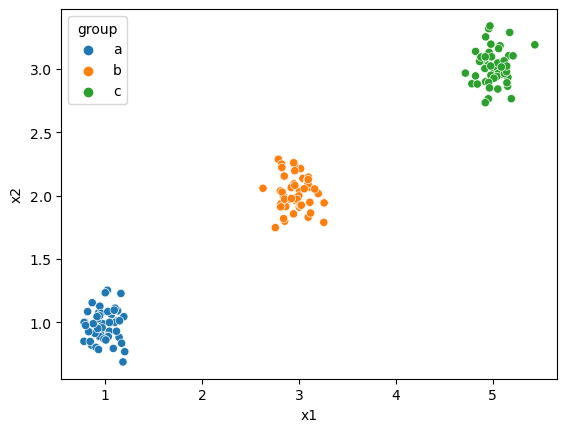

In [98]:
df0_125_scatter = sns.scatterplot(data = df0_125, x = "x1", y = "x2", hue = "group")
df0_125_scatter 

<Axes: xlabel='x1', ylabel='x2'>

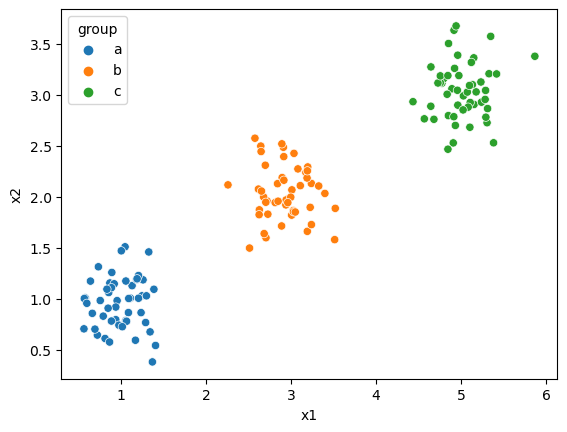

In [99]:
df0_25_scatter = sns.scatterplot(data = df0_25, x = "x1", y = "x2", hue = "group")
df0_25_scatter 

<Axes: xlabel='x1', ylabel='x2'>

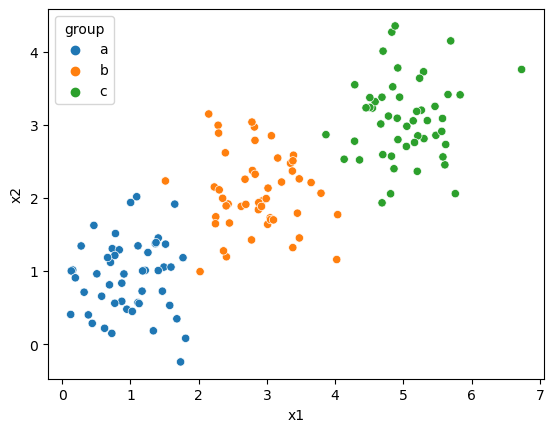

In [100]:
df0_5_scatter = sns.scatterplot(data = df0_5, x = "x1", y = "x2", hue = "group")
df0_5_scatter 

<Axes: xlabel='x1', ylabel='x2'>

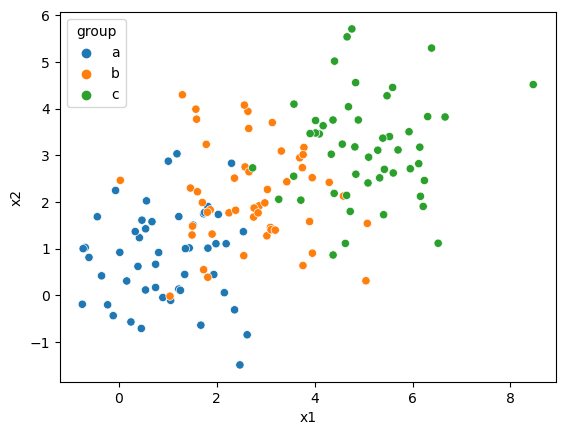

In [101]:
df1_0_scatter = sns.scatterplot(data = df1_0, x = "x1", y = "x2", hue = "group")
df1_0_scatter 

<Axes: xlabel='x1', ylabel='x2'>

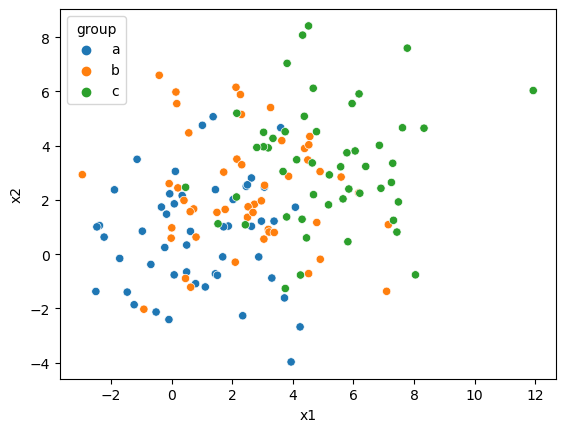

In [102]:
df2_0_scatter = sns.scatterplot(data = df2_0, x = "x1", y = "x2", hue = "group")
df2_0_scatter 

3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
---
Answer: As the noise grew, distinguishing the elbow became more and more difficult. It was very clear because of the sudden drop off into an almost flat curve when noise was 0.125, but that sharp turn into a flat curve became more and more subtle. As a result, my ability to definitively select a $k$ became harder as well.

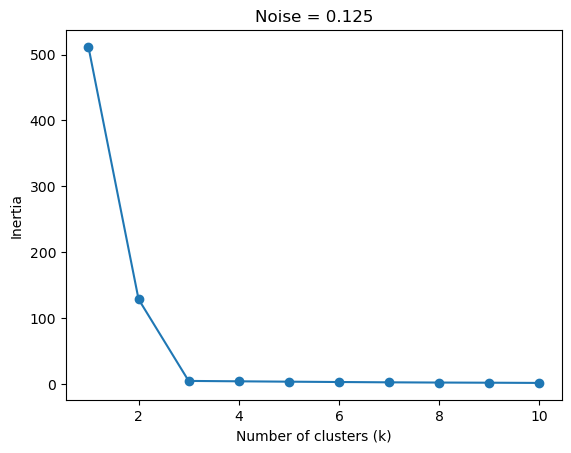

In [103]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_125[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.125")
plt.show()

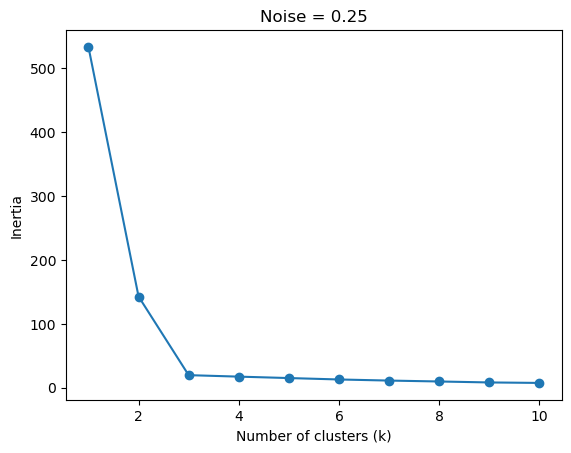

In [104]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_25[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.25")
plt.show()

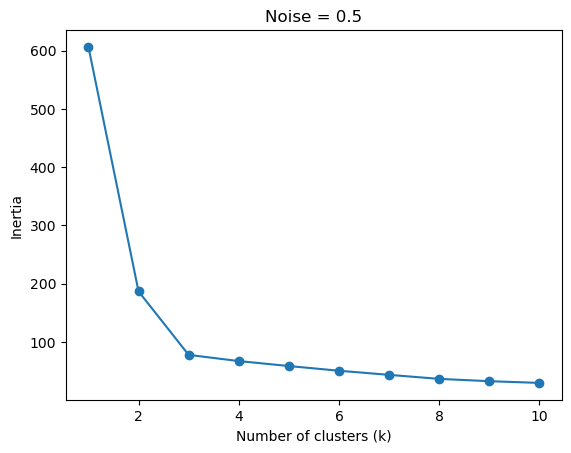

In [105]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df0_5[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 0.5")
plt.show()

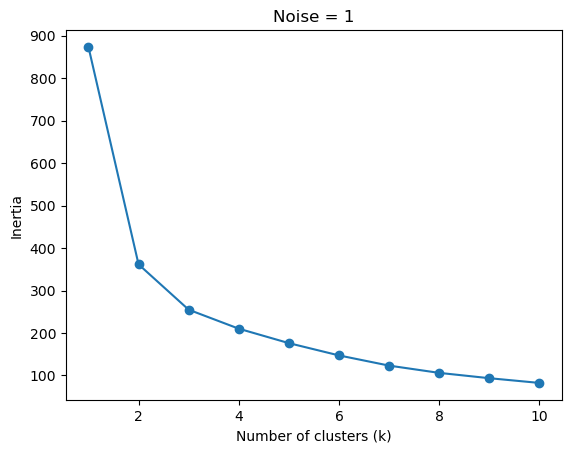

In [106]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df1_0[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 1")
plt.show()

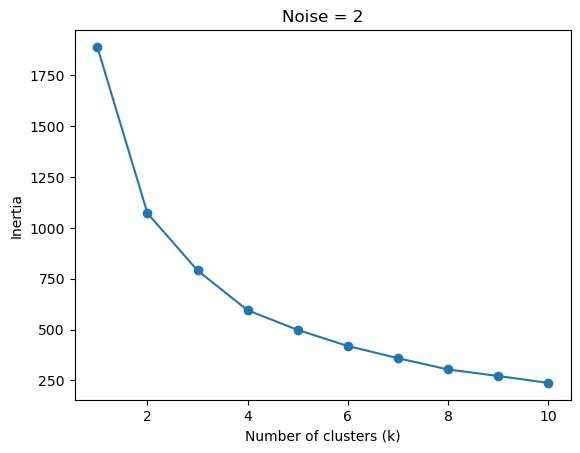

In [107]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(df2_0[["x1", "x2"]])
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = 2")
plt.show()

4. Explain the intuition of the elbow, using this numerical simulation as an example.
---
Answer: The elbow is where adding more clusters stops reducing inertia by a lot. In this simulation, inertia drops a lot until there are three clusters, then the graph starts to flatten because adding more clusters barely helps. As noise increases, the points spread into each other and the groups become harder to distinguish, so the elbow becomes less obvious and choosing a good $k$ becomes harder

# Question 2


In [108]:
SIPRI_df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
filtered_SIPRI_df = SIPRI_df[SIPRI_df["Year"] == 2020].dropna()
print(filtered_SIPRI_df.info())
print(filtered_SIPRI_df.describe())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB
None
             index    Year  Spending (2020 USD)  Percent of GDP  \
count   148.000000   148.0           148.000000      148.000000   
mean   2831.256757  2020.0         13153.747670        0.019619   
std    1654.299355     0.0         68005.236120        0.015033   
min      3

2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
---
Many of the points look almost like a vertical line because the US spends so much more overall that the other countries get squeezed together on the graph. The groups mainly differ in spending per capita, while the US is the green point in its own cluster. Its total spending is much higher, and its spending per capita is also high, though it is not the highest.

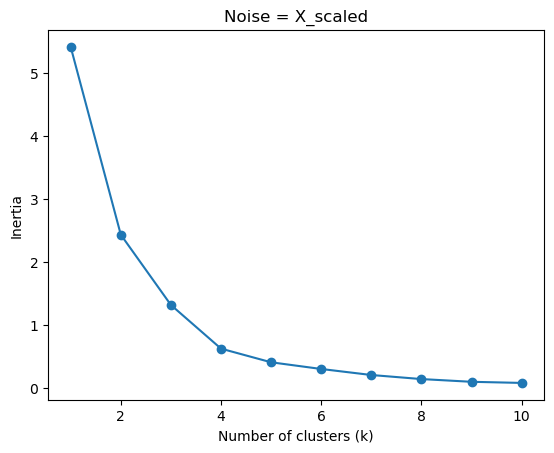

In [109]:
cols = ["Spending (2020 USD)", "Spending per Capita"]

X = filtered_SIPRI_df[cols]
X_scaled = (X - X.min()) / (X.max() - X.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = X_scaled")
plt.show()

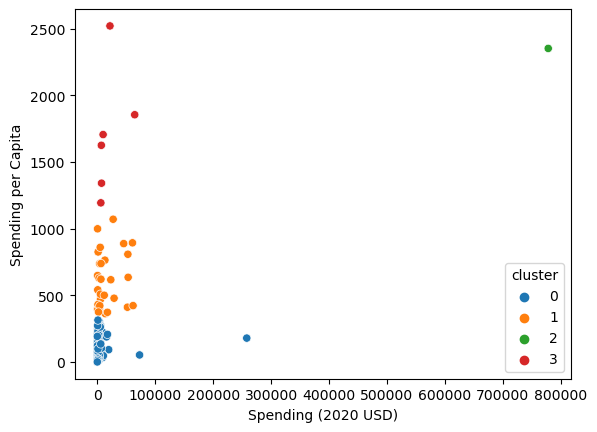

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                      30.0   17077.591354  20583.053357     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   
3                       6.0   19443.362047  22861.507114    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          2294.039665    5857.060906   26296.001003   61712.537169   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          7023.251766    8624.225729   18857.070183   64558.400000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                      30.0   607.478618  206.928757   362.467076   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1         422.208252   579.004604   757.328513  1070.623322  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541

In [110]:
model = KMeans(n_clusters=4, random_state=100, n_init=10)
filtered_SIPRI_df["cluster"] = model.fit_predict(X_scaled)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="tab10"
)
plt.show()

filtered_SIPRI_df.groupby("cluster")[cols].describe()

3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
---
The graph had a less obvious elbow, so I decided to try using k = 3 for the scatterplot. The scatterplot shows a positive relationship: countries that spend a larger percentage of their budget on their military also have a higher percentage of GDP. The groups roughly separate into low, medium, and high spending shares. Compared to part 2, these groups show how much each country is spending towards their military, rather than total spending.

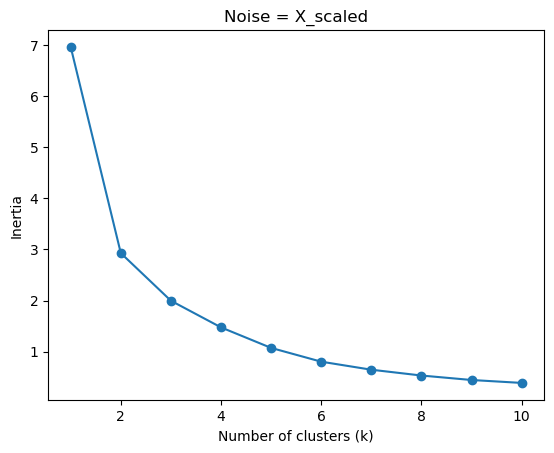

In [111]:
cols = ["Percent of Government Spending", "Percent of GDP"]

X = filtered_SIPRI_df[cols]
X_scaled = (X - X.min()) / (X.max() - X.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Noise = X_scaled")
plt.show()

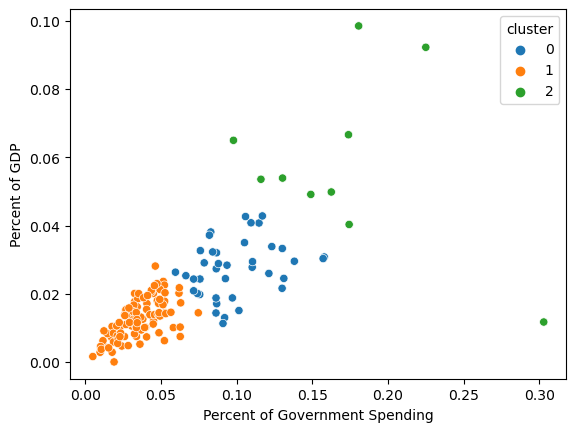

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 99.0  0.035777  0.014549  0.004896   
2                                 10.0  0.171289  0.058725  0.097882   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

In [112]:
model = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster"] = model.fit_predict(X_scaled)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    palette="tab10"
)
plt.show()

filtered_SIPRI_df.groupby("cluster")[cols].describe()

4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
---
Using all four variables, I chose $k$ = 3 because the scree plot starts to flatten around there. Compared to part 2, the US is no longer in its own cluster and is now grouped with five other countries with high spending per capita. Compared to part 3, the groups now account for spending amounts as well as spending shares. The blue group generally has lower spending shares, the orange group has high spending per capita, and the green group has higher spending shares without especially high spending per capita. Some colors overlap in the graphs because each graph only shows two of the four variables used to form the clusters. The comparison with part 2 also reflects using three clusters instead of four.

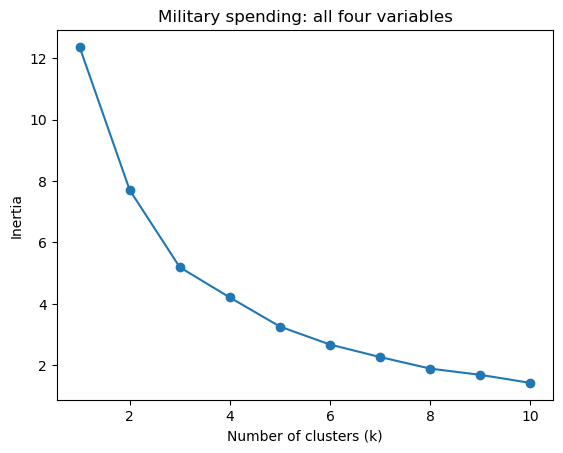

In [113]:
cols_all = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

X_all = filtered_SIPRI_df[cols_all]
X_all_scaled = (X_all - X_all.min()) / (X_all.max() - X_all.min())

inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_all_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Military spending: all four variables")
plt.show()

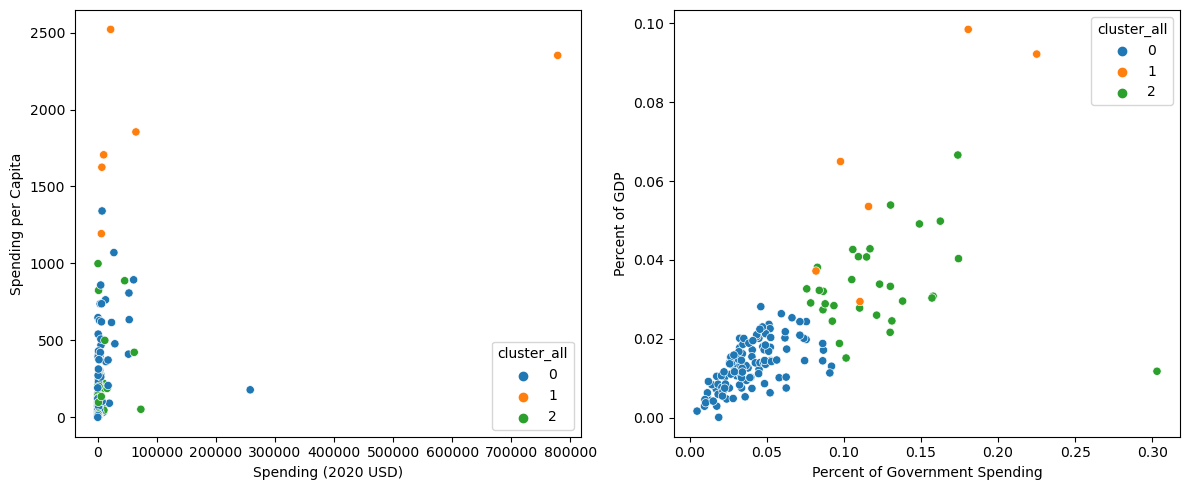

Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                          31.0    8786.086602   17901.909108   162.373364   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             467.787851   1404.787234   7739.166193   72937.064048   

            Spending per Capita               ...  \
                          count         mean  ...   
cluster_all                                   ...   
0                         111.0   196.926833  ...   
1                           6.0  1875.150751  ...   
2                          31.0   212.689100  ...   

            Percent of Government Spending           Percent of GDP            \
                                       75%       max          count      mean   
cluster_all                                                                     
0                                 0.050505  0.092044          111.0  0.013419   
1                                 0.164503  0.225050            6.0  0.062634   
2                                 0.134663  0.303027           31.0  0.033492   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  

[3 rows x 32 columns]

,Country,cluster_all,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,1,778397.2,2351.631858,0.081976,0.037179


In [114]:

model = KMeans(n_clusters=3, random_state=100, n_init=10)
filtered_SIPRI_df["cluster_all"] = model.fit_predict(X_all_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster_all",
    palette="tab10",
    ax=axes[0]
)

sns.scatterplot(
    data=filtered_SIPRI_df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster_all",
    palette="tab10",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

display(filtered_SIPRI_df.groupby("cluster_all")[cols_all].describe())

display(
    filtered_SIPRI_df.loc[
        filtered_SIPRI_df["Country"] == "United States of America",
        ["Country", "cluster_all"] + cols_all
    ]
)

5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
---
Yes, the $k$-MC algorithm helped me see that high total military spending doesn't always mean a country spends a high percentage of its GDP or government budget. In part 2 I could clearly see the US stood out in its own cluster, but in part 3 it grouped countries by their spending shares. Using all four variables showed how countries could have similar spending per capita but different shares. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [115]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]